In [ ]:
import streamlit as st
import torch
import torch.nn as nn
import numpy as np
import cv2
from PIL import Image
import torchvision.transforms as transforms
from gtts import gTTS
import base64
import os

# =========================
# ⚙️ CONFIG (Matches Your Training Code)
# =========================
MODEL_PATH = "crnn_model_final.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMG_HEIGHT = 32

# EXACT CHARACTER SET FROM YOUR TRAINING
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1  # 68

# =========================
# 🧠 CRNN MODEL (Exact Architecture from Training)
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super(CRNN, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 64, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(128, 256, 3, 1, 1), nn.ReLU(),
            nn.Conv2d(256, 256, 3, 1, 1), nn.ReLU(), nn.MaxPool2d((2, 1)),
            nn.Conv2d(256, 512, 3, 1, 1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(), nn.MaxPool2d((2, 1)),
            nn.Conv2d(512, 512, 2, 1, 0), nn.ReLU()
        )
        self.rnn = nn.LSTM(512, 256, bidirectional=True, num_layers=2, batch_first=True)
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.cnn(x)
        b, c, h, w = x.size()
        # Squeeze the height dimension (which is 1 after the last CNN layer)
        x = x.squeeze(2).permute(0, 2, 1)  # (B, W, C)
        x, _ = self.rnn(x)
        x = self.fc(x)
        return x # Inference doesn't strictly need log_softmax if using argmax

# =========================
# 📥 HELPER FUNCTIONS
# =========================
@st.cache_resource
def load_model():
    model = CRNN(NUM_CLASSES).to(DEVICE)
    if os.path.exists(MODEL_PATH):
        try:
            model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
            model.eval()
            return model
        except Exception as e:
            st.error(f"Error loading state_dict: {e}")
    else:
        st.error(f"Checkpoint not found at {MODEL_PATH}")
    return None

def preprocess(img):
    """Matches OCRDataset.__getitem__ logic exactly."""
    img = img.convert("L") # Grayscale
    w, h = img.size
    new_w = max(int(IMG_HEIGHT * w / h), 1)
    img = img.resize((new_w, IMG_HEIGHT), Image.Resampling.LANCZOS)
    
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])
    return transform(img).unsqueeze(0).to(DEVICE)

def decode_predictions(preds):
    """Matches your decode function."""
    preds = preds.argmax(2).cpu().numpy()[0]
    text = ""
    prev = -1
    for p in preds:
        if p != prev and p != 0:
            text += idx_to_char.get(p, "")
        prev = p
    return text

def play_audio(text):
    """Converts text to speech and plays it in the browser."""
    if text.strip():
        tts = gTTS(text=text, lang='en')
        tts.save("speech.mp3")
        with open("speech.mp3", "rb") as f:
            data = f.read()
            b64 = base64.b64encode(data).decode()
            md = f'<audio autoplay="true" src="data:audio/mp3;base64,{b64}">'
            st.markdown(md, unsafe_allow_html=True)

# =========================
# 🚀 STREAMLIT UI
# =========================
st.set_page_config(page_title="OCR to Speech", layout="centered")
st.title("📸 Camera OCR & Speech")
st.write("Capture a clear image of text to hear it spoken.")

model = load_model()

# Camera Capture
cam_image = st.camera_input("Capture Image")

if cam_image and model:
    # 1. Load and Preprocess
    img = Image.open(cam_image)
    input_tensor = preprocess(img)
    
    # 2. Predict
    with torch.no_grad():
        preds = model(input_tensor)
        extracted_text = decode_predictions(preds)
    
    # 3. Display Results
    st.subheader("Extracted Text:")
    if extracted_text.strip():
        st.success(extracted_text)
        
        # 4. Convert to Speech
        if st.button("🔊 Play Text"):
            with st.spinner("Generating audio..."):
                play_audio(extracted_text)
    else:
        st.warning("No text detected. Please try again with better lighting or focus.")

# Ensure gtts is installed
if __name__ == "__main__":
    try:
        import gtts
    except ImportError:
        os.system('pip install gTTS')

In [ ]:
### import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms

# =========================
# CONFIG
# =========================
LABEL_FILE = "Dataset/labels.txt"
IMG_HEIGHT = 32
BATCH_SIZE = 32
EPOCHS = 30
LR = 0.0003
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SAVE_PATH = "crnn_model_final.pth"

# =========================
# CHAR SET
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
char_to_idx = {c: i+1 for i, c in enumerate(CHARS)}
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1  # +1 for blank

# =========================
# DATASET
# =========================
class OCRDataset(Dataset):
    def __init__(self, label_file):
        self.samples = []

        with open(label_file, "r", encoding="utf-8") as f:
            for line in f:
                path, text = line.strip().split("\t")
                if len(text) > 0:
                    self.samples.append((path, text))

        self.transform = transforms.Compose([
            transforms.Grayscale(),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,))
        ])

    def encode(self, text):
        return [char_to_idx[c] for c in text if c in char_to_idx]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, text = self.samples[idx]
        img = Image.open(path).convert("RGB")

        w, h = img.size
        new_w = max(int(IMG_HEIGHT * w / h), 1)
        img = img.resize((new_w, IMG_HEIGHT), Image.Resampling.LANCZOS)

        img = self.transform(img)
        label = torch.tensor(self.encode(text), dtype=torch.long)

        return img, label, len(label), text

# =========================
# COLLATE
# =========================
def collate_fn(batch):
    images, labels, lengths, texts = zip(*batch)

    max_w = max(img.shape[2] for img in images)

    padded_imgs = []
    for img in images:
        c, h, w = img.shape
        padded = torch.zeros(c, h, max_w)
        padded[:, :, :w] = img
        padded_imgs.append(padded)

    images = torch.stack(padded_imgs)
    labels = torch.cat(labels)
    lengths = torch.tensor(lengths)

    return images, labels, lengths, texts

# =========================
# MODEL
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(
            input_size=512,
            hidden_size=256,
            num_layers=2,
            bidirectional=True,
            batch_first=True
        )

        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.cnn(x)
        b, c, h, w = x.size()

        assert h == 1, "Height must be 1 after CNN"

        x = x.squeeze(2).permute(0,2,1)  # (B, W, C)
        x, _ = self.rnn(x)
        x = self.fc(x)

        return x.log_softmax(2)

# =========================
# DECODER
# =========================
def decode(preds):
    preds = preds.argmax(2).cpu().numpy()
    results = []

    for pred in preds:
        prev = -1
        text = ""

        for p in pred:
            if p != prev and p != 0:
                text += idx_to_char.get(p, "")
            prev = p

        results.append(text)

    return results

# =========================
# TRAIN
# =========================
dataset = OCRDataset(LABEL_FILE)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

model = CRNN(NUM_CLASSES).to(DEVICE)

criterion = nn.CTCLoss(blank=0, zero_infinity=True)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

best_loss = float("inf")

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    print(f"\n=== Epoch {epoch+1}/{EPOCHS} ===")

    for i, (imgs, labels, label_lengths, texts) in enumerate(loader):
        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)
        label_lengths = label_lengths.to(DEVICE)

        preds = model(imgs)  # (B, W, C)
        preds = preds.permute(1,0,2)  # (W, B, C)

        input_lengths = torch.full(
            size=(imgs.size(0),),
            fill_value=preds.size(0),
            dtype=torch.long
        ).to(DEVICE)

        loss = criterion(preds, labels, input_lengths, label_lengths)

        optimizer.zero_grad()
        loss.backward()

        # 🔥 IMPORTANT (fix exploding gradients)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5)

        optimizer.step()

        total_loss += loss.item()

        if (i+1) % 50 == 0:
            print(f"Batch {i+1}, Loss: {loss.item():.4f}")

    avg_loss = total_loss / len(loader)
    print(f"Epoch Loss: {avg_loss:.4f}")

    # =========================
    # SAMPLE CHECK
    # =========================
    model.eval()
    with torch.no_grad():
        imgs, _, _, texts = next(iter(loader))
        imgs = imgs.to(DEVICE)

        preds = model(imgs)
        decoded = decode(preds)

        print("\nSample Predictions:")
        for gt, pr in zip(texts[:5], decoded[:5]):
            print(f"GT: {gt} | Pred: {pr}")

    # =========================
    # SAVE BEST MODEL
    # =========================
    if avg_loss < best_loss:
        best_loss = avg_loss
        torch.save(model.state_dict(), SAVE_PATH)
        print("✅ Model Saved!")

print("\n🎉 Training Completed Successfully!")

In [ ]:
import cv2
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
import torchvision.transforms as transforms

# =========================
# CONFIG
# =========================
MODEL_PATH = "crnn_model_final.pth"
IMAGE_PATH = "anip.png"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_HEIGHT = 32

# =========================
# CHAR SET
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1

# =========================
# MODEL (same as training)
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(512,256,bidirectional=True,num_layers=2,batch_first=True)
        self.fc = nn.Linear(512,num_classes)

    def forward(self,x):
        x = self.cnn(x)
        b,c,h,w = x.size()
        x = x.squeeze(2).permute(0,2,1)
        x,_ = self.rnn(x)
        x = self.fc(x)
        return x.log_softmax(2)

# =========================
# LOAD MODEL
# =========================
model = CRNN(NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

print("✅ Model Loaded")

# =========================
# TRANSFORM
# =========================
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# =========================
# DECODER
# =========================
def decode(pred):
    pred = pred.argmax(2).cpu().numpy()[0]

    prev = -1
    text = ""

    for p in pred:
        if p != prev and p != 0:
            text += idx_to_char.get(p, "")
        prev = p

    return text

# =========================
# PREPROCESS IMAGE (OpenCV)
# =========================
image = cv2.imread(IMAGE_PATH)
orig = image.copy()

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Better binarization
thresh = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    15, 8
)

# Morphological dilation to group text
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15,3))
dilated = cv2.dilate(thresh, kernel, iterations=1)

# =========================
# FIND TEXT REGIONS
# =========================
contours, _ = cv2.findContours(
    dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

boxes = []
for cnt in contours:
    x,y,w,h = cv2.boundingRect(cnt)

    # Filter noise
    if w > 50 and h > 15:
        boxes.append((x,y,w,h))

# Sort top-to-bottom
boxes = sorted(boxes, key=lambda b: (b[1], b[0]))

print(f"Detected {len(boxes)} text regions")

# =========================
# OCR EACH REGION
# =========================
results = []

for i, (x,y,w,h) in enumerate(boxes):
    crop = gray[y:y+h, x:x+w]

    # Resize keeping aspect ratio
    h0, w0 = crop.shape
    new_w = int(IMG_HEIGHT * w0 / h0)
    crop = cv2.resize(crop, (new_w, IMG_HEIGHT))

    pil_img = Image.fromarray(crop)
    img_tensor = transform(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        preds = model(img_tensor)
        text = decode(preds)

    if len(text.strip()) > 0:
        results.append((y, text))

    # Draw bounding box
    cv2.rectangle(orig, (x,y), (x+w, y+h), (0,255,0), 2)

# =========================
# SORT & PRINT FINAL TEXT
# =========================
results = sorted(results, key=lambda x: x[0])

print("\n🧾 FINAL EXTRACTED TEXT:\n")
for _, text in results:
    print(text)

# =========================
# SHOW RESULT
# =========================
cv2.imshow("Detected Text", orig)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [ ]:
# Tranining 30.03.2026

In [1]:
# =========================
# COMPLETE TRAIN + TEST PIPELINE
# =========================
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms
import cv2

# =========================
# CONFIG
# =========================
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

IMG_HEIGHT = 32
BATCH_SIZE = 32
EPOCHS = 20
LR = 0.0003

MODEL_PATH = "crnn_model_final.pth"
LABEL_FILE = "dataset2/labels.txt"
TEST_IMAGE = "anip.png"

# =========================
# CHARSET
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
char_to_idx = {c: i+1 for i, c in enumerate(CHARS)}
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1

# =========================
# DATASET
# =========================
class OCRDataset(Dataset):
    def __init__(self, label_file):
        self.samples = []
        with open(label_file, "r", encoding="utf-8") as f:
            for line in f:
                path, text = line.strip().split("\t")
                self.samples.append((path, text))

        self.transform = transforms.Compose([
            transforms.Grayscale(),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,))
        ])

    def encode(self, text):
        return [char_to_idx[c] for c in text if c in char_to_idx]

    def __getitem__(self, idx):
        path, text = self.samples[idx]

        img = Image.open(path).convert("RGB")
        w, h = img.size
        new_w = max(int(IMG_HEIGHT * w / h), 1)
        img = img.resize((new_w, IMG_HEIGHT))

        img = self.transform(img)
        label = torch.tensor(self.encode(text), dtype=torch.long)

        return img, label, len(label)

    def __len__(self):
        return len(self.samples)

def collate_fn(batch):
    imgs, labels, lengths = zip(*batch)

    max_w = max(img.shape[2] for img in imgs)
    padded_imgs = []

    for img in imgs:
        c, h, w = img.shape
        temp = torch.zeros(c, h, max_w)
        temp[:, :, :w] = img
        padded_imgs.append(temp)

    return torch.stack(padded_imgs), torch.cat(labels), torch.tensor(lengths)

# =========================
# MODEL
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(512,256, num_layers=2, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.cnn(x)
        x = x.squeeze(2).permute(0,2,1)
        x,_ = self.rnn(x)
        x = self.fc(x)
        return x.log_softmax(2)

# =========================
# DECODER
# =========================
def decode(preds):
    preds = preds.argmax(2).cpu().numpy()
    results = []

    for pred in preds:
        prev = -1
        text = ""
        for p in pred:
            if p != prev and p != 0:
                text += idx_to_char.get(p, "")
            prev = p
        results.append(text)

    return results

# =========================
# LINE SEGMENTATION
# =========================
def segment_lines(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray,255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY_INV,
        15,5
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (60,3))
    dilated = cv2.dilate(thresh, kernel, iterations=1)

    contours,_ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    lines = []
    for cnt in contours:
        x,y,w,h = cv2.boundingRect(cnt)
        if h > 8 and w > 30:
            lines.append((y, gray[y:y+h, x:x+w]))

    lines = sorted(lines, key=lambda x: x[0])
    return [l for _,l in lines]

# =========================
# TEST FUNCTION
# =========================
def run_test(model, tag="TEST"):
    print(f"\n🔍 {tag}")

    model.eval()
    lines = segment_lines(TEST_IMAGE)

    print(f"\n🧾 Detected {len(lines)} lines\n")

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    with torch.no_grad():
        for i, line in enumerate(lines):
            img = Image.fromarray(line)

            w,h = img.size
            new_w = max(int(IMG_HEIGHT * w / h), 1)
            img = img.resize((new_w, IMG_HEIGHT))

            img = transform(img).unsqueeze(0).to(DEVICE)

            preds = model(img)
            text = decode(preds)[0]

            print(f"Line {i+1}: {text}")

# =========================
# LOAD DATA
# =========================
dataset = OCRDataset(LABEL_FILE)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

model = CRNN(NUM_CLASSES).to(DEVICE)

# Load existing model if exists
if os.path.exists(MODEL_PATH):
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
    print("✅ Loaded existing model")

criterion = nn.CTCLoss(blank=0, zero_infinity=True)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# =========================
# 🔥 TEST BEFORE TRAINING
# =========================
run_test(model, tag="BEFORE TRAINING")

# =========================
# TRAIN LOOP
# =========================
for epoch in range(1, EPOCHS+1):
    model.train()
    total_loss = 0

    print(f"\n🚀 Epoch {epoch}/{EPOCHS}")

    for imgs, labels, label_lengths in loader:
        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)
        label_lengths = label_lengths.to(DEVICE)

        preds = model(imgs).permute(1,0,2)

        input_lengths = torch.full((imgs.size(0),), preds.size(0)).to(DEVICE)

        loss = criterion(preds, labels, input_lengths, label_lengths)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5)
        optimizer.step()

        total_loss += loss.item()

    print(f"📉 Loss: {total_loss/len(loader):.4f}")

    # =========================
    # SAVE AFTER EVERY EPOCH
    # =========================
    torch.save(model.state_dict(), MODEL_PATH)
    print("✅ Model Saved")

    # =========================
    # TEST AFTER EVERY EPOCH
    # =========================
    run_test(model, tag=f"AFTER EPOCH {epoch}")

✅ Loaded existing model

🔍 BEFORE TRAINING

🧾 Detected 39 lines

Line 1:  @K@j@@_l.ElEg_@._l@@lE@3.@lNR_S l Kfj jES
Line 2:  S5l__l2Z@e7zg j
Line 3:  f. 9l lUlDj7_QR 8llf IH_lBXlHllJfr SfGlflR@J
Line 4:   lHlfltdI Bd7HIHlf
Line 5:  ASS1sten PfOfeSSO7. DcDaJLcTt Of FineTCG. UnlVcTSel BuS1n1SS SCl1OOlj KdTjaE. Ra1gead.
Line 6:  Em1ejl. krutikea.SaWaTt@ubS.OTB.i
Line 7:   lHlqISlHHtll1dIH @i0If
Line 8:  PGDM T1 FiT1a01CG. U1ivcFSal BuSiTGSS SCh00 EaJjet RaiBad eheardstrel.
Line 9:  Emei. 1eFShMa7heD.SOTi@tbS.O7B.1T
Line 10:   lPaTfidj lal1aTdUl
Line 11:  PGDM T1 FiT1a01CG. U1ivcFSal BuSiTGSS SCh00 EaJjet RaiBad eheardstrel.
Line 12:  ET1eail. PdJt1TajS1h.leheTatl@tbS.0FB.101
Line 13:  SaHT8bi gaTMaI
Line 14:  PGDM T1 FiT1af1CG UmiVTSal BuS1TCSS SCh00. Eejeat RaiBad Me1eardshtF l.
Line 15:  Emei. SatTabh.aBa7WaJ@bS.O7B.iT
Line 16:   f.0SlfHCf
Line 17:  Thc benKhB idtlstry is deTB010g g7OU1G-bTCak1Tg FcfOImS. Wjt1 a fOCS On th Clicnt eS thc
Line 18:  pJlnmdly drivcr. tustocrs thet erc tccli

KeyboardInterrupt: 

In [2]:
pip install wordfreq

   ---------------------------------------- 0.0/56.8 MB ? eta -:--:--
    --------------------------------------- 0.8/56.8 MB 7.1 MB/s eta 0:00:08
   -- ------------------------------------- 4.2/56.8 MB 13.8 MB/s eta 0:00:04
   ------ --------------------------------- 8.9/56.8 MB 17.1 MB/s eta 0:00:03
   -------- ------------------------------- 12.3/56.8 MB 16.6 MB/s eta 0:00:03
   ----------- ---------------------------- 17.0/56.8 MB 17.9 MB/s eta 0:00:03
   ------------- -------------------------- 19.4/56.8 MB 17.2 MB/s eta 0:00:03
   -------------- ------------------------- 21.2/56.8 MB 15.4 MB/s eta 0:00:03
   --------------- ------------------------ 22.0/56.8 MB 14.0 MB/s eta 0:00:03
   ---------------- ----------------------- 22.8/56.8 MB 12.8 MB/s eta 0:00:03
   ---------------- ----------------------- 23.6/56.8 MB 11.8 MB/s eta 0:00:03
   ----------------- ---------------------- 24.4/56.8 MB 11.1 MB/s eta 0:00:03
   ----------------- ---------------------- 25.2/56.8 MB 10.5 MB/

In [1]:
pip install transformers sentencepiece

   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   --------- ------------------------------ 0.3/1.1 MB ? eta -:--:--
   ---------------------------------------- 1.1/1.1 MB 6.1 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [1]:
# =========================
# FULL OCR + GPT CORRECTION
# =========================
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms
import cv2
from tqdm import tqdm
import difflib
from wordfreq import zipf_frequency

# 🔥 GPT MODEL
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# =========================
# CONFIG
# =========================
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

IMG_HEIGHT = 32
BATCH_SIZE = 32
EPOCHS = 10
LR = 0.0003

MODEL_PATH = "crnn_model_final.pth"
LABEL_FILE = "dataset2/labels.txt"
TEST_IMAGE = "anip.png"

# =========================
# LOAD GPT CORRECTION MODEL
# =========================
print("🔄 Loading Language Model...")
tokenizer = AutoTokenizer.from_pretrained("vennify/t5-base-grammar-correction")
lm_model = AutoModelForSeq2SeqLM.from_pretrained(
    "vennify/t5-base-grammar-correction"
).to(DEVICE)
print("✅ Language Model Loaded")

def gpt_correct(text):
    if len(text.strip()) < 5:
        return text

    input_text = "grammar: " + text
    inputs = tokenizer.encode(input_text, return_tensors="pt").to(DEVICE)

    outputs = lm_model.generate(
        inputs,
        max_length=256,
        num_beams=5,
        early_stopping=True
    )

    corrected = tokenizer.decode(outputs[0], skip_special_tokens=True)
    return corrected

# =========================
# CHARSET
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
char_to_idx = {c: i+1 for i, c in enumerate(CHARS)}
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1

# =========================
# DICTIONARY
# =========================
WORD_LIST = set([
    "banking","industry","assistant","professor","department","finance",
    "university","business","school","email","customer","technology",
    "management","service","digital","data","analysis","learning",
    "artificial","intelligence","model","training","network"
])

def correct_word(word):
    if len(word) < 3:
        return word

    word_lower = word.lower()
    if word_lower in WORD_LIST:
        return word

    candidates = difflib.get_close_matches(word_lower, WORD_LIST, n=3, cutoff=0.6)
    if not candidates:
        return word

    best = max(candidates, key=lambda w: zipf_frequency(w, 'en'))

    if word[0].isupper():
        return best.capitalize()
    return best

def correct_sentence(text):
    return " ".join(correct_word(w) for w in text.split())

# =========================
# MODEL
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(512,256, num_layers=2, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.cnn(x)
        x = x.squeeze(2).permute(0,2,1)
        x,_ = self.rnn(x)
        x = self.fc(x)
        return x.log_softmax(2)

# =========================
# BEAM SEARCH
# =========================
def beam_search_decoder(probs, beam_width=5):
    probs = probs.squeeze(0)
    T, C = probs.shape

    beams = [("", 0.0)]

    for t in range(T):
        new_beams = []
        for prefix, score in beams:
            for c in range(C):
                char = "" if c == 0 else idx_to_char.get(c, "")
                new_prefix = prefix + char
                new_score = score + probs[t, c].item()
                new_beams.append((new_prefix, new_score))

        beams = sorted(new_beams, key=lambda x: x[1], reverse=True)[:beam_width]

    return beams[0][0]

# =========================
# SEGMENTATION
# =========================
def segment_lines(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray,255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY_INV,
        15,5
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (60,3))
    dilated = cv2.dilate(thresh, kernel, iterations=1)

    contours,_ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    lines = []
    for cnt in contours:
        x,y,w,h = cv2.boundingRect(cnt)
        if h > 8 and w > 30:
            lines.append((y, gray[y:y+h, x:x+w]))

    lines = sorted(lines, key=lambda x: x[0])
    return [l for _,l in lines]

# =========================
# 🔥 FINAL TEST FUNCTION
# =========================
def run_test(model, tag="TEST"):
    print(f"\n🔍 {tag}")

    model.eval()
    lines = segment_lines(TEST_IMAGE)

    print(f"\n🧾 Detected {len(lines)} lines\n")

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    with torch.no_grad():
        for i, line in enumerate(lines):
            img = Image.fromarray(line)

            w,h = img.size
            new_w = max(int(IMG_HEIGHT * w / h), 1)
            img = img.resize((new_w, IMG_HEIGHT))

            img = transform(img).unsqueeze(0).to(DEVICE)

            preds = model(img)

            # 🔥 PIPELINE
            raw = beam_search_decoder(preds)
            dict_fixed = correct_sentence(raw)
            final = gpt_correct(dict_fixed)

            print(f"\nLine {i+1}")
            print("RAW:   ", raw)
            print("DICT:  ", dict_fixed)
            print("FINAL: ", final)

# =========================
# LOAD MODEL
# =========================
model = CRNN(NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

# =========================
# RUN TEST
# =========================
run_test(model, tag="FINAL OCR OUTPUT")

C:\Users\manis\ocr_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🔄 Loading Language Model...


C:\Users\manis\ocr_env\Lib\site-packages\huggingface_hub\file_download.py:130: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\manis\.cache\huggingface\hub\models--vennify--t5-base-grammar-correction. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|███████████████████████████| 260/260 [00:01<00:00, 195.35it/s, Materializing param=shared

✅ Language Model Loaded

🔍 FINAL OCR OUTPUT

🧾 Detected 39 lines


Line 1
RAW:     @K@j@@_l.ElEg_@._l@@lE@3.@lNR_S  l Kfj jES
DICT:   @K@j@@_l.ElEg_@._l@@lE@3.@lNR_S l Kfj jES
FINAL:  @K@j@@_l.ElEg_@._l@@lE@3.@lNR_S l Kfj jES.

Line 2
RAW:      S5l__l2Z@e7zgg j
DICT:   S5l__l2Z@e7zgg j
FINAL:  S5l__l2Z@e7zgg j.

Line 3
RAW:     f. 9l lUlDj7_QR 8llf IH_lBXlHllJfr  SfGlflR@J
DICT:   f. 9l lUlDj7_QR 8llf IH_lBXlHllJfr SfGlflR@J
FINAL:  9l lUlDj7_QR 8llf IH_lBXlHllJfr SfGlflR@J.

Line 4
RAW:      lHlfltdI Bd7HIHlf
DICT:   lHlfltdI Bd7HIHlf
FINAL:  lHlfltdI Bd7HIHlfltdI

Line 5
RAW:      ASS1sten  PfOfeSSO7. DcDaJLcTt Of FineTCG. UnlVcTSel BuS1n1SS SCl1OOlj KdTjjaE. RRa1gead.
DICT:   Assistant Professor DcDaJLcTt Of FineTCG. UnlVcTSel Business School KdTjjaE. RRa1gead.
FINAL:  Assistant Professor DcDaJLcTt Of FineTCG. UnlVcTSel Business School KdTjjaE.

Line 6
RAW:     Em1ejl. krutikea.SaWaTt@ubS.OTB.i
DICT:   Em1ejl. krutikea.SaWaTt@ubS.OTB.i
FINAL:  Em1ejl. krutikea.SaWaTt@ubS.OTB.ie.

Li

✅ Loaded existing model

🔍 BEFORE TRAINING

🧾 Detected 39 lines

Line 1:  @K@j@@_l.ElEg_@._l@@lE@3.@lNR_S l Kfj jES
Line 2:  S5l__l2Z@e7zg j
Line 3:  f. 9l lUlDj7_QR 8llf IH_lBXlHllJfr SfGlflR@J
Line 4:   lHlfltdI Bd7HIHlf
Line 5:  ASS1sten PfOfeSSO7. DcDaJLcTt Of FineTCG. UnlVcTSel BuS1n1SS SCl1OOlj KdTjaE. Ra1gead.
Line 6:  Em1ejl. krutikea.SaWaTt@ubS.OTB.i
Line 7:   lHlqISlHHtll1dIH @i0If
Line 8:  PGDM T1 FiT1a01CG. U1ivcFSal BuSiTGSS SCh00 EaJjet RaiBad eheardstrel.
Line 9:  Emei. 1eFShMa7heD.SOTi@tbS.O7B.1T
Line 10:   lPaTfidj lal1aTdUl
Line 11:  PGDM T1 FiT1a01CG. U1ivcFSal BuSiTGSS SCh00 EaJjet RaiBad eheardstrel.
Line 12:  ET1eail. PdJt1TajS1h.leheTatl@tbS.0FB.101
Line 13:  SaHT8bi gaTMaI
Line 14:  PGDM T1 FiT1af1CG UmiVTSal BuS1TCSS SCh00. Eejeat RaiBad Me1eardshtF l.
Line 15:  Emei. SatTabh.aBa7WaJ@bS.O7B.iT
Line 16:   f.0SlfHCf
Line 17:  Thc benKhB idtlstry is deTB010g g7OU1G-bTCak1Tg FcfOImS. Wjt1 a fOCS On th Clicnt eS thc
Line 18:  pJlnmdly drivcr. tustocrs thet erc tccli

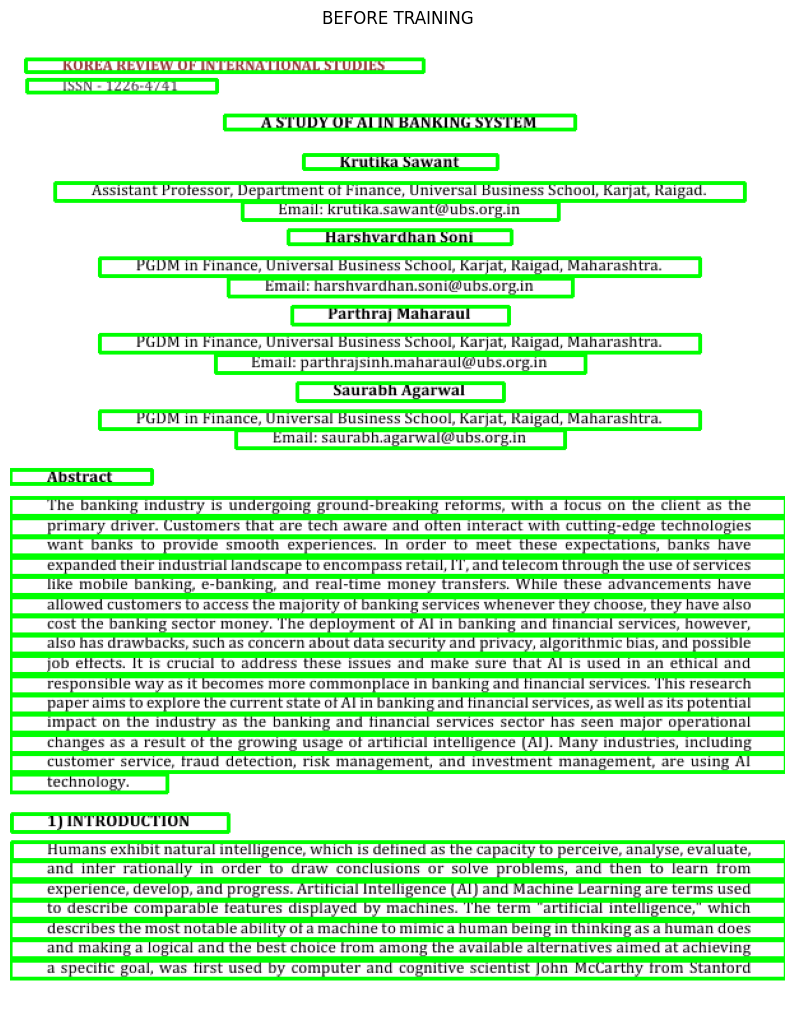


🚀 Epoch 1/5


100%|█████████████████████████████████████████████████████████████████| 938/938 [6:14:14<00:00, 23.94s/it, loss=0.0121]


Epoch Loss: 0.2783
💾 Saved: crnn_epoch_1.pth

🔍 AFTER EPOCH 1

🧾 Detected 39 lines

Line 1:   tttlili lsylsl llf lyjklfilllltil gllllEg
Line 2:  ssll e llfeigl
Line 3:  f gjUl gif dllh Bhlllt gjglB
Line 4:   lrrttld galamt
Line 5:  issistdant rrofessor  Departnnentofrindnce lniversal Businss scho0l kdrjat  Raigad.
Line 6:    kmail krutikdsawant@ubs.0rgin
Line 7:   darglilardllidtm gigmf
Line 8:    p6rlv4 in rinanlce lniversal dusiness schoolkarjat  @aigdd  Mahardshtrd.
Line 9:    Email  harshvardhdan.Soni@ubs.orgin
Line 10:   partiraj dalidrdul
Line 11:    p6rlv4 in rinanlce lniversal dusiness schoolkarjat  @aigdd  Mahardshtrd.
Line 12:   Enail parthrajsinhnnlaharaul@ubS.0rginl
Line 13:   saurdlbli igarMal
Line 14:   p6rlv4 in rinanlce lniversal business scho0lkarjat  @aigad  vaharashtra
Line 15:    Emailsaurabhagarwal@ubs.orgin
Line 16:   flbgfratgt
Line 17:   rhc banking indtstry is undergoing groundrbrcaking reforns  witi d focts on thg clientas the
Line 18:  prinmary drivsrtustonne

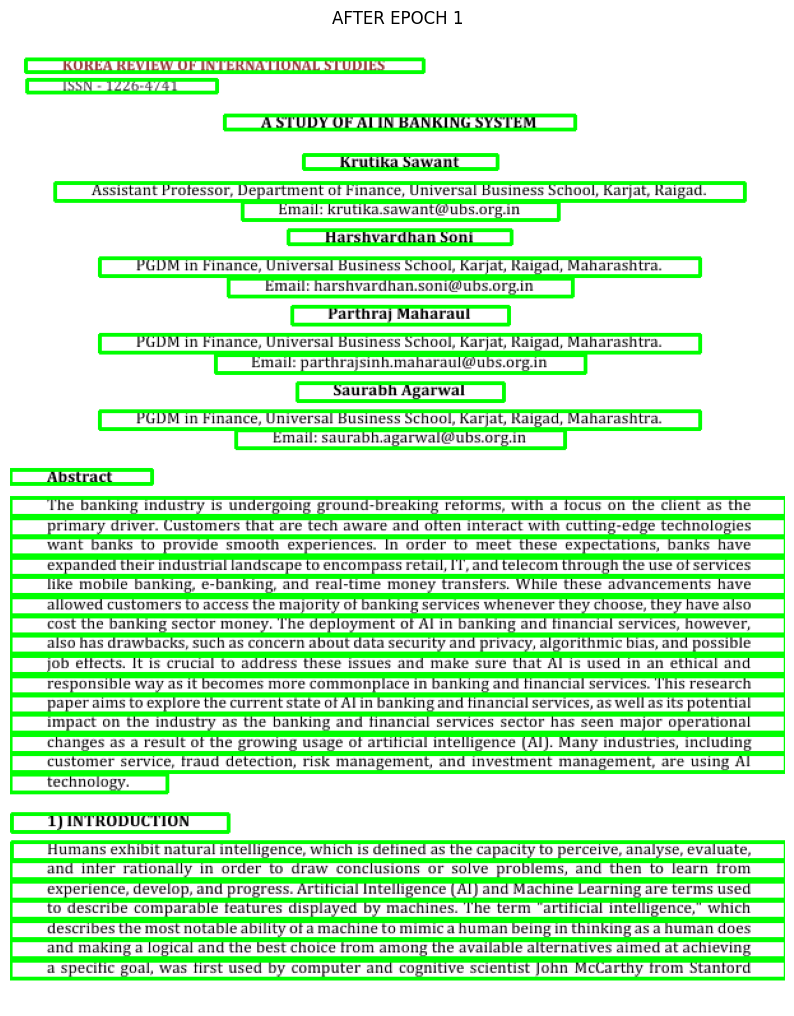


🚀 Epoch 2/5


100%|██████████████████████████████████████████████████████████████████| 938/938 [5:45:07<00:00, 22.08s/it, loss=0.467]


Epoch Loss: 0.1576
💾 Saved: crnn_epoch_2.pth

🔍 AFTER EPOCH 2

🧾 Detected 39 lines

Line 1:   lttlllf lsylsly tlr lrjklltfilllllll gltllllES
Line 2:   lsslil e l lferdrgl
Line 3:   f glllll grdll llh Bilhlllt glglElf
Line 4:   lruttltd galamt
Line 5:   fssistdant rrofessor  Departnnent of rindnce  tniversal  Businss school drjat  Raigad.
Line 6:  bnmailt krutikdsawart@ubs.0rgin
Line 7:   llargslitardltdt gigmf
Line 8:    p6ljv it rinanlce lniversal business school karjat @aigad  Maharashtrd.
Line 9:   EmailharshvardhdanS0ni@ubsS.orgin
Line 10:   fartiraj alhadraul
Line 11:    p6ljv it rinanlce lniversal business school karjat @aigad  Maharashtrd.
Line 12:   Enailt parthrajsinhnlaharaul@ubS.0rginl
Line 13:   saurabli igarMal
Line 14:   p6ljv it rinanlce lniversal business school karjat  @aigad  vaharashtra
Line 15:   Enailsaurabh.agarwal@ubs.orgin
Line 16:   filtgtratgt
Line 17:  rhc banking indtstry is undergoing groundrbrcaking reforms  witi a focus on thg client as the
Line 18:  prin

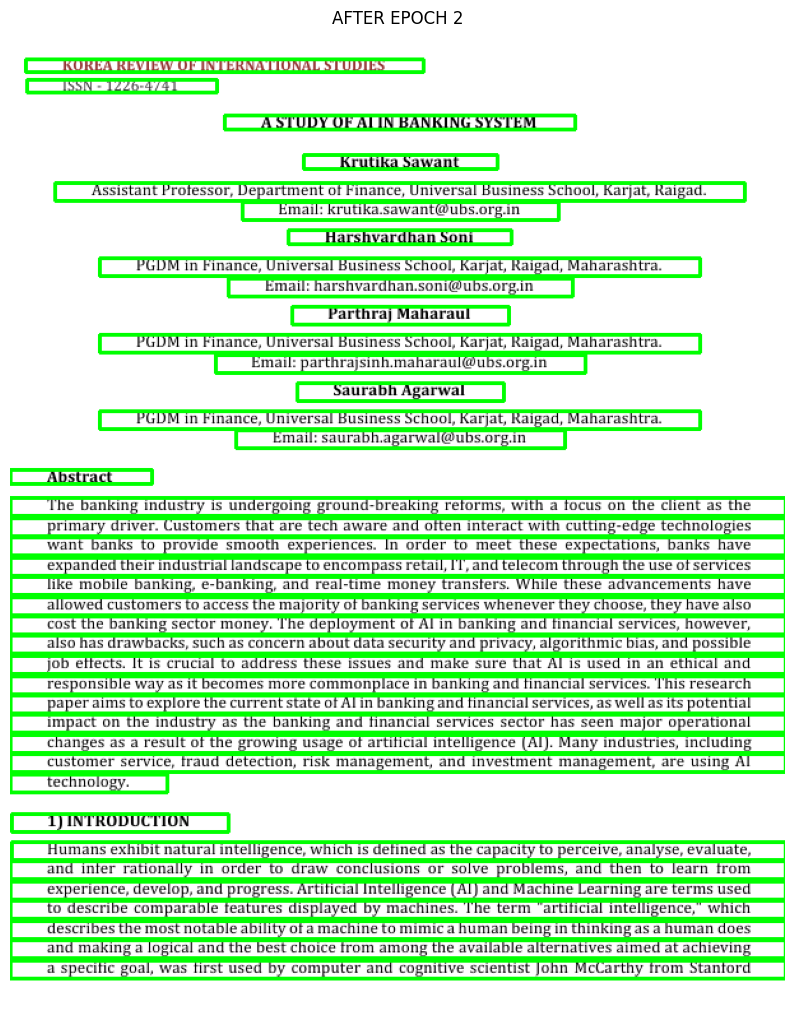


🚀 Epoch 3/5


100%|██████████████████████████████████████████████████████████████████| 938/938 [6:02:55<00:00, 23.22s/it, loss=0.145]


Epoch Loss: 0.1380
💾 Saved: crnn_epoch_3.pth

🔍 AFTER EPOCH 3

🧾 Detected 39 lines

Line 1:   lgt@lf laylsyy tr trggklttisllltylk glllS
Line 2:   lssil e l ggfsdrgl
Line 3:  f gjUj iFdl l Bihlllilt giggEWf
Line 4:   lruttld gatramt
Line 5:  fssistdant rrofessor Departnnent of rinance tniversal businss school kdrjat  Raigad
Line 6:  bniailt krutika.saWant@ubs.0rgin
Line 7:   darsligardltat gigmf
Line 8:  pGv it rinanicelniversal business schoolkarjat  @aigad  Maharashtrd
Line 9:   Ennaiz harshvardhanS0ni@ubs.orgin
Line 10:   partihraj Malharaul
Line 11:  pGv it rinanicelniversal business schoolkarjat  @aigad  Maharashtrd
Line 12:   Enail parthrajsinhnnaharaul@ubS.0rginl
Line 13:   saurabli igarWal
Line 14:  pGv it rinanicelniversal business schoolkarjat  @aigad  Maharashtra
Line 15:  Ennaisaurabh.agarwal@ubs.orgin
Line 16:   filgtratgt
Line 17:  rhe banking indtstry is undergoing groundrbreaking refornns  witi a focus on thg client as the
Line 18:  prinnary drivsr tustonners that drc te

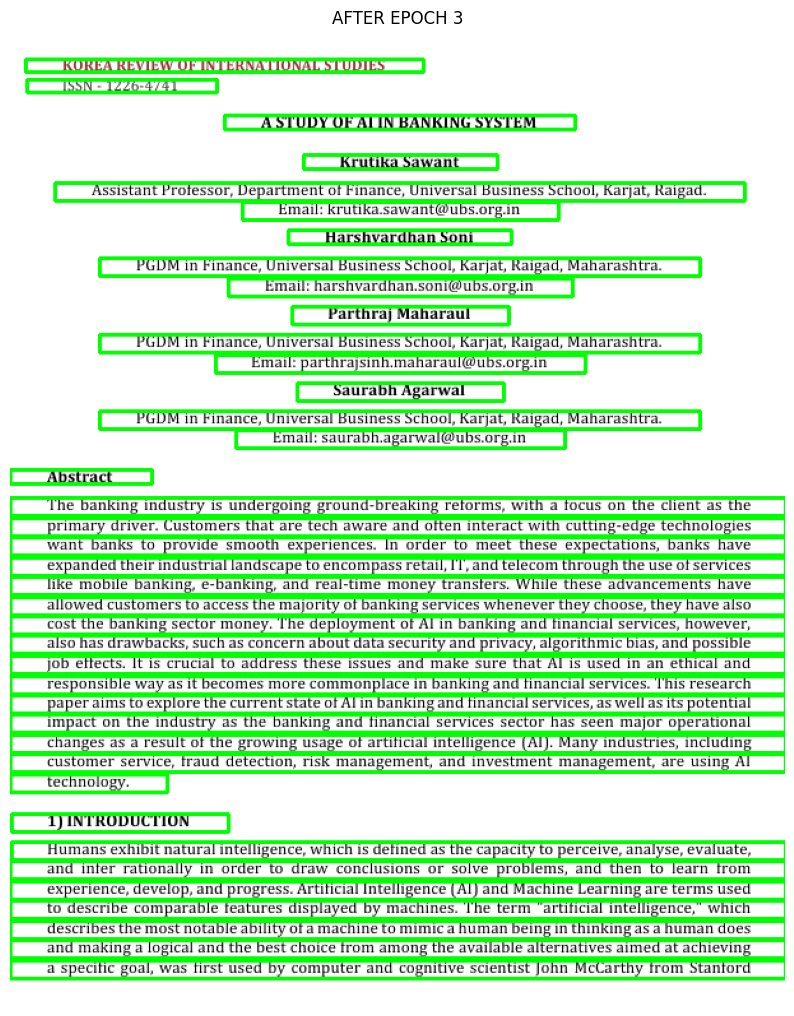


🚀 Epoch 4/5


100%|██████████████████████████████████████████████████████████████████| 938/938 [5:49:35<00:00, 22.36s/it, loss=0.057]


Epoch Loss: 0.1261
💾 Saved: crnn_epoch_4.pth

🔍 AFTER EPOCH 4

🧾 Detected 39 lines

Line 1:   lgt@Ef layisly t lttablltfi lltlltfik gDlES
Line 2:   fssli a lggfrrrg
Line 3:  f gtuli girfl l Biihlllilt giggE
Line 4:   lruttlstd gatat
Line 5:    fssistant rrofessor Departnnent of finance tniversal Business school karjat  Raigad
Line 6:  Eniailt krutikasaWant@ubs.0rgin
Line 7:   darslirrardltatt ggtf
Line 8:    pGv it rinance lniversal btsiness schoolkarjat  Raigad  vaharashtra
Line 9:   Ennail.harshvardhanSoni@ubs.orgin
Line 10:   parthraj alharaul
Line 11:    pGv it rinance lniversal btsiness schoolkarjat  Raigad  vaharashtra
Line 12:   Enlailz parthrajsinhnaharaul@ubs.0rgin
Line 13:   saurabl fgarWal
Line 14:    pGv it rinance lniversal business school karjat  Raigad  Maharashtra
Line 15:  Ennailsatrabhagarwal@ubs.orgin
Line 16:   fiitgtratgt
Line 17:  rhe banking indtstry is undergoing groundrbrcaking refornns  with a focus on the client as the
Line 18:   prinnary drivsr tustonners th

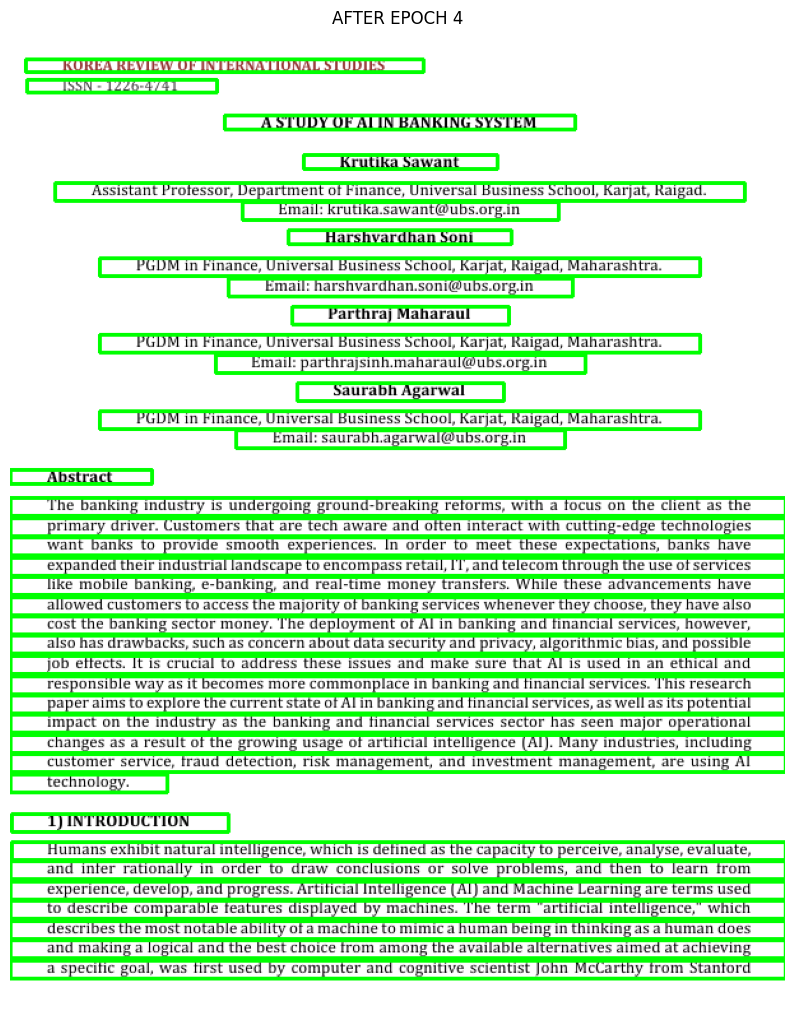


🚀 Epoch 5/5


100%|█████████████████████████████████████████████████████████████████| 938/938 [5:50:41<00:00, 22.43s/it, loss=0.0107]


Epoch Loss: 0.1152
💾 Saved: crnn_epoch_5.pth

🔍 AFTER EPOCH 5

🧾 Detected 39 lines

Line 1:   lftlllf ayisyy tl tigaftfillllfit gyllS
Line 2:   fssll a lofedryyl
Line 3:   f ggul @ir ill lll Biihllllilt giggEj
Line 4:   lfrutfltd gatatt
Line 5:     fssistant rrofessor lepartnnent of rindnce  tniversal business school  karjat kaigad
Line 6:    bniailt krutikasawant@ubs0rgin
Line 7:    ragrsligardltatt gigtf
Line 8:   ptlv it rinanice lniversal business school karjat Raigad  vaharashtrd
Line 9:   Enmail harshvardhdnsni@ubs.orgin
Line 10:   rartihraj alharaul
Line 11:   ptlv it rinanice lniversal business school karjat Raigad  vaharashtrd
Line 12:    knailt parthrajsinhnahdraul@ubs.0rgin
Line 13:   saurabli fgaral
Line 14:   ptlv it rinanice lniversal business school karjat Raigad  vaharashtra
Line 15:   Enmailsaturabhagarwal@ubs.orgin
Line 16:   figfratgt
Line 17: lhe banking indtstry is undergoing groundrbreaking reforms  witi a focus on ths client as the
Line 18:   prinnary driver tust

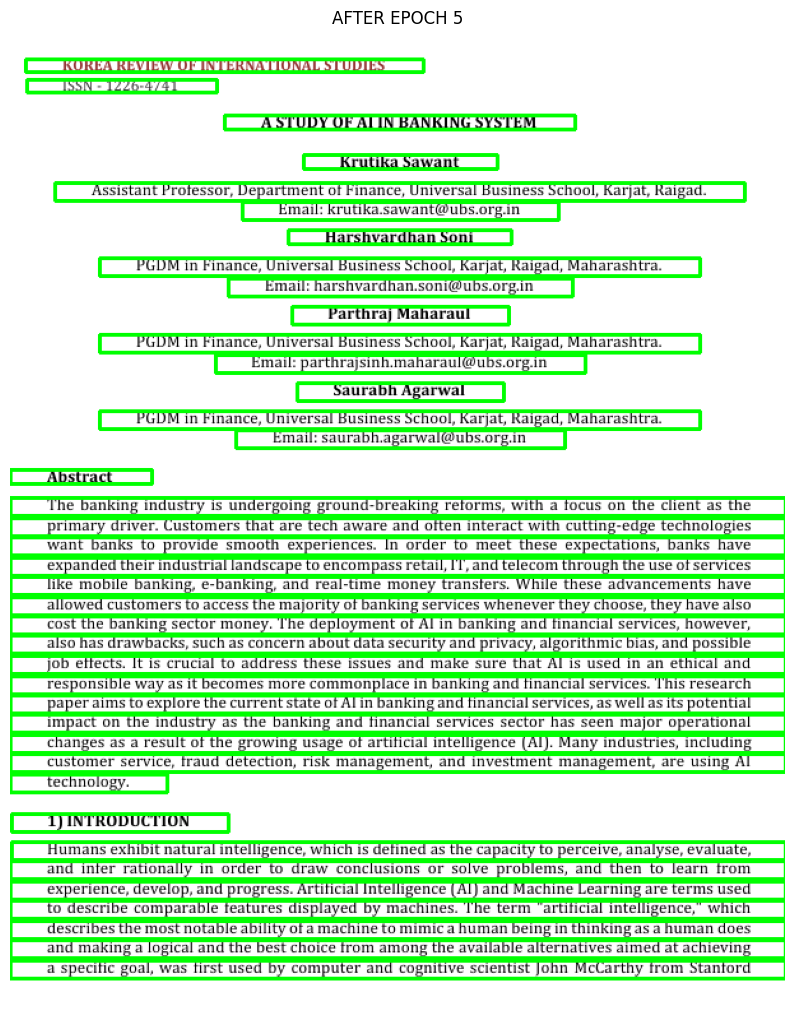


🎉 DONE


In [3]:
# =========================
# 🔥 CONTINUE TRAIN + VISUAL TEST
# =========================

import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm

# =========================
# CONFIG
# =========================
MODEL_PATH = "crnn_model_final.pth"   # your trained model
LABEL_FILE = "dataset2/labels.txt"
TEST_IMAGE = "anip.png"

IMG_HEIGHT = 32
BATCH_SIZE = 32
EPOCHS = 5
LR = 0.0001

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

os.makedirs("debug_lines", exist_ok=True)

# =========================
# CHARSET (MUST MATCH)
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
char_to_idx = {c: i+1 for i,c in enumerate(CHARS)}
idx_to_char = {i+1:c for i,c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1

# =========================
# DATASET
# =========================
class OCRDataset(Dataset):
    def __init__(self, label_file):
        self.samples = []

        with open(label_file, "r", encoding="utf-8") as f:
            for line in f:
                path, text = line.strip().split("\t")
                if len(text) > 0:
                    self.samples.append((path, text))

        self.transform = transforms.Compose([
            transforms.Grayscale(),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,))
        ])

    def encode(self, text):
        return [char_to_idx[c] for c in text if c in char_to_idx]

    def __getitem__(self, idx):
        path, text = self.samples[idx]

        img = Image.open(path).convert("RGB")

        w,h = img.size
        new_w = max(int(IMG_HEIGHT * w / h), 1)
        img = img.resize((new_w, IMG_HEIGHT))

        img = self.transform(img)
        label = torch.tensor(self.encode(text), dtype=torch.long)

        return img, label, len(label), text

    def __len__(self):
        return len(self.samples)

def collate_fn(batch):
    imgs, labels, lengths, texts = zip(*batch)

    max_w = max(img.shape[2] for img in imgs)

    padded_imgs = []
    for img in imgs:
        c,h,w = img.shape
        pad = torch.zeros(c,h,max_w)
        pad[:,:,:w] = img
        padded_imgs.append(pad)

    imgs = torch.stack(padded_imgs)
    labels = torch.cat(labels)
    lengths = torch.tensor(lengths)

    return imgs, labels, lengths, texts

# =========================
# MODEL
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(512,256,2,bidirectional=True,batch_first=True)
        self.fc = nn.Linear(512,num_classes)

    def forward(self,x):
        x = self.cnn(x)
        x = x.squeeze(2).permute(0,2,1)
        x,_ = self.rnn(x)
        x = self.fc(x)
        return x.log_softmax(2)

# =========================
# DECODER
# =========================
def decode(preds):
    preds = preds.argmax(2).cpu().numpy()
    results = []

    for pred in preds:
        prev = -1
        text = ""

        for p in pred:
            if p != prev and p != 0:
                text += idx_to_char.get(p, "")
            prev = p

        results.append(text)

    return results

# =========================
# LINE DETECTION
# =========================
def segment_lines(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray,255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY_INV,
        15,5
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT,(60,3))
    dilated = cv2.dilate(thresh,kernel,1)

    contours,_ = cv2.findContours(dilated,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

    lines=[]
    boxes=[]

    for cnt in contours:
        x,y,w,h = cv2.boundingRect(cnt)
        if h>8 and w>30:
            lines.append((y,gray[y:y+h,x:x+w]))
            boxes.append((x,y,w,h))

    lines = sorted(lines,key=lambda x:x[0])
    boxes = sorted(boxes,key=lambda x:x[1])

    return img, [l for _,l in lines], boxes

# =========================
# TEST FUNCTION
# =========================
def run_test(model, tag="TEST"):
    print(f"\n🔍 {tag}")
    model.eval()

    img, lines, boxes = segment_lines(TEST_IMAGE)
    print(f"\n🧾 Detected {len(lines)} lines\n")

    vis = img.copy()

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    for i,(line,(x,y,w,h)) in enumerate(zip(lines,boxes)):

        # save line image
        cv2.imwrite(f"debug_lines/line_{i}.png", line)

        # draw box
        cv2.rectangle(vis,(x,y),(x+w,y+h),(0,255,0),2)

        pil_img = Image.fromarray(line)

        w0,h0 = pil_img.size
        new_w = max(int(IMG_HEIGHT*w0/h0),1)
        pil_img = pil_img.resize((new_w, IMG_HEIGHT))

        inp = transform(pil_img).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            preds = model(inp)
            text = decode(preds)[0]

        print(f"Line {i+1}: {text}")

    # show image
    plt.figure(figsize=(10,15))
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.title(tag)
    plt.axis("off")
    plt.show()

# =========================
# LOAD MODEL
# =========================
model = CRNN(NUM_CLASSES).to(DEVICE)

if os.path.exists(MODEL_PATH):
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
    print("✅ Loaded existing model")

# =========================
# TRAIN SETUP
# =========================
dataset = OCRDataset(LABEL_FILE)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

criterion = nn.CTCLoss(blank=0, zero_infinity=True)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# =========================
# 🔥 TEST BEFORE TRAINING
# =========================
run_test(model, "BEFORE TRAINING")

# =========================
# TRAIN LOOP
# =========================
for epoch in range(EPOCHS):

    print(f"\n🚀 Epoch {epoch+1}/{EPOCHS}")

    model.train()
    total_loss = 0

    loop = tqdm(loader)

    for imgs, labels, label_lengths, _ in loop:
        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)
        label_lengths = label_lengths.to(DEVICE)

        preds = model(imgs).permute(1,0,2)

        input_lengths = torch.full(
            (imgs.size(0),),
            preds.size(0),
            dtype=torch.long
        ).to(DEVICE)

        loss = criterion(preds, labels, input_lengths, label_lengths)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5)
        optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    print(f"Epoch Loss: {total_loss/len(loader):.4f}")

    # SAVE MODEL
    save_path = f"crnn_epoch_{epoch+1}.pth"
    torch.save(model.state_dict(), save_path)
    print(f"💾 Saved: {save_path}")

    # TEST AFTER EPOCH
    run_test(model, f"AFTER EPOCH {epoch+1}")

print("\n🎉 DONE")